# Brain Tumor MRI Classification with Neural Networks and Deep Learning

**Course:** MLAI 504 – Neural Networks and Deep Learning (2026–2027)  
**Author:** karam jammal & yorgo bou fayad 
**Dataset:** [Brain Tumor MRI Dataset](https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset) (Kaggle, CC0: Public Domain)

## Project goal

Build a neural network that classifies a brain MRI slice into one of four classes: **glioma**, **meningioma**, **pituitary tumor** or **no tumor**. The project follows a systematic approach: data exploration and cleaning, step-by-step model creation, hyperparameter tuning and transfer learning, with every decision explained.

> ⚠️ **Disclaimer:** this is an academic project. The model is not a medical device and must not be used for diagnosis.

## Table of contents

0. Environment setup
1. Dataset selection and description
2. Data exploration and preprocessing
3. Step-by-step model creation
4. Hyperparameter tuning
5. Transfer learning
6. Integration of course topics
7. Evaluation and interpretation
8. Final results and conclusions
9. References

---
# 0. Environment setup

The notebook runs in a Python virtual environment with TensorFlow / Keras. This section imports the libraries, fixes the random seeds and records the library versions so the results can be reproduced.

In [1]:
import os
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import cv2
import imagehash
import kagglehub
import tensorflow as tf
import keras
import keras_tuner as kt

# Reproducibility: one call fixes the Python, NumPy and TensorFlow random seeds
SEED = 42
keras.utils.set_random_seed(SEED)

# Record the environment
versions = {
    "Python": platform.python_version(),
    "TensorFlow": tf.__version__,
    "Keras": keras.__version__,
    "Keras backend": keras.backend.backend(),
    "Keras Tuner": kt.__version__,
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "OpenCV": cv2.__version__,
    "ImageHash": imagehash.__version__,
    "kagglehub": kagglehub.__version__,
}
for name, version in versions.items():
    print(f"{name:<14}: {version}")

# GPU check (0 is expected on a Windows laptop; the GPU comes in Phase 3 via Colab)
gpus = tf.config.list_physical_devices("GPU")
print(f"\nGPUs available: {len(gpus)}")

c:\Users\hp\Desktop\miai504_Project\brain-tumor-mri-classification\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python        : 3.12.4
TensorFlow    : 2.21.0
Keras         : 3.15.1
Keras backend : tensorflow
Keras Tuner   : 1.4.8
NumPy         : 2.5.4
Pandas        : 3.1.1
scikit-learn  : 1.9.1
OpenCV        : 5.0.0
ImageHash     : 4.3.2
kagglehub     : 1.0.3

GPUs available: 0


**Download the dataset.** `kagglehub` downloads the dataset from Kaggle the first time and reuses the local copy afterwards. The folder tree below confirms the data is in place and gives a first image count per class.

In [2]:
# Download the dataset (only the first time; later runs reuse the local copy)
DATA_DIR = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print("Dataset location:", DATA_DIR, "\n")

# Print the folder tree with the number of images in each folder
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")
for root, dirs, files in sorted(os.walk(DATA_DIR)):
    depth = root[len(DATA_DIR):].count(os.sep)
    n_images = sum(f.lower().endswith(IMAGE_EXTENSIONS) for f in files)
    label = f"  ({n_images} images)" if n_images else ""
    print(f"{'    ' * depth}{os.path.basename(root)}/{label}")

100%|██████████| 157M/157M [08:23<00:00, 327kB/s] 

Extracting files...


Dataset location: C:\Users\hp\.cache\kagglehub\datasets\masoudnickparvar\brain-tumor-mri-dataset\versions\2 

2/
    Testing/
        glioma/  (400 images)
        meningioma/  (400 images)
        notumor/  (400 images)
        pituitary/  (400 images)
    Training/
        glioma/  (1400 images)
        meningioma/  (1400 images)
        notumor/  (1400 images)
        pituitary/  (1400 images)


---
# 1. Dataset selection and description

## Source
We use the **Brain Tumor MRI Dataset** published on Kaggle by Masoud Nickparvar (version 2, CC0: Public Domain). It combines three public datasets: **Figshare**, **SARTAJ** and **Br35H**. The "no tumor" images come from Br35H, and the author replaced SARTAJ's glioma images, which were found to be mislabeled, with images from Figshare.

## Why this dataset
Brain tumors are diagnosed mainly from MRI scans, and the tumor type matters because each type is treated differently. Reading scans takes expert time, so a model that classifies them automatically could support radiologists, for example by flagging the scans that need attention first. The dataset also fits this project well:
- it is an image dataset, which suits CNNs and transfer learning with pretrained models such as ResNet50;
- it is a manageable size (7,200 images, about 150 MB), so models train in minutes on a GPU;
- it has real data-quality problems to solve (different image sizes, black borders, and duplicate images across the training and test sets), which are handled in Section 2.

## Size, features and target
- **Size:** 7,200 JPEG images, provided in a `Training` folder (5,600) and a `Testing` folder (1,600).
- **Features:** the pixel values of each MRI slice. The scans are grayscale and come in different resolutions, so they are resized to a common size during preprocessing.
- **Target variable:** the tumor class, given by the folder name, with four categories:

| Class | Description |
|---|---|
| **glioma** | Tumor that grows from the glial (supporting) cells of the brain; can be slow-growing or aggressive |
| **meningioma** | Tumor of the meninges, the membranes around the brain; usually benign |
| **pituitary** | Tumor of the pituitary gland at the base of the brain; usually benign, but can affect hormones and vision |
| **notumor** | Healthy brain scan with no tumor |

**Image index.** We build a table with one row per image (file path, class and the folder it came from). It is used for counting here and for all preprocessing in Section 2.

In [3]:
from pathlib import Path

CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

# One row per image: file path, class label and the folder it came from
records = []
for split in ["Training", "Testing"]:
    for label in CLASSES:
        for path in sorted((Path(DATA_DIR) / split / label).iterdir()):
            if path.suffix.lower() in IMAGE_EXTENSIONS:
                records.append({"path": str(path), "label": label, "original_split": split})

df = pd.DataFrame(records)
print(f"Total images: {len(df)}")

# Number of images per class in each folder
counts = pd.crosstab(df["label"], df["original_split"], margins=True, margins_name="Total")
counts[["Training", "Testing", "Total"]]

Total images: 7200


original_split,Training,Testing,Total
label,,,
glioma,1400,400,1800
meningioma,1400,400,1800
notumor,1400,400,1800
pituitary,1400,400,1800
Total,5600,1600,7200


**Sample images.** Four random images per class, with each image's size in pixels (width × height).

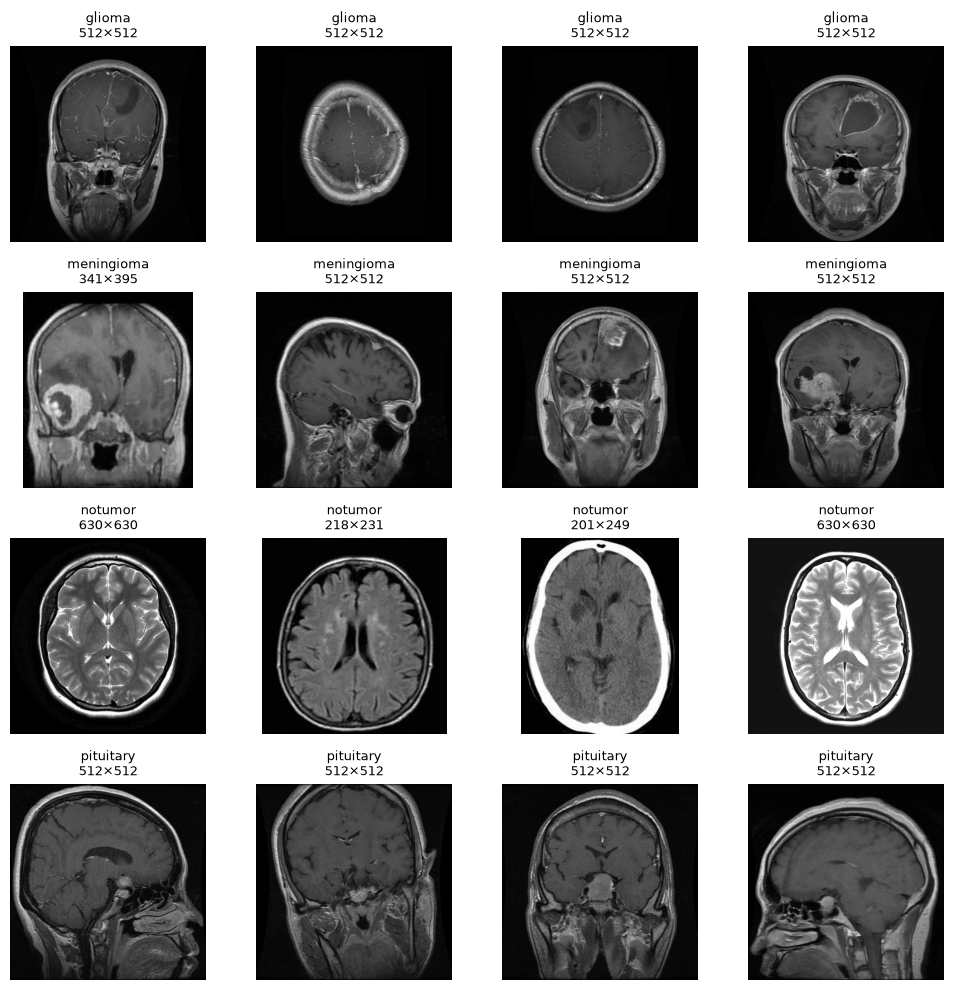

In [4]:
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(10, 10))

for row, label in enumerate(CLASSES):
    samples = df[df["label"] == label].sample(4, random_state=SEED)
    for col, path in enumerate(samples["path"]):
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        ax = axes[row, col]
        ax.imshow(img, cmap="gray")
        ax.set_title(f"{label}\n{img.shape[1]}×{img.shape[0]}", fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

**Observations**
- The four classes are perfectly balanced (1,800 images each), so accuracy is a fair main metric and no class weighting is needed.
- Image sizes vary between images, so all images must be resized to one common size before training.
- Many scans have black borders around the head, which carry no information and can be cropped.
- The scans show different views of the head (from above, from the front and from the side) and different contrast levels, because the images come from three different sources.